In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_parquet("../data/processed/online_retail_clean.parquet")
df_cohort = df[df["InvoiceDate"] < "2011-12-01"].copy()

print(f"Tổng số dòng giao dịch: {len(df_cohort):,}")
print(f"Tổng số khách hàng trong phạm vi Cohort: {df_cohort['CustomerID'].nunique():,} khách")
print(f"Khoảng thời gian: {df_cohort['InvoiceDate'].min().date()} -> {df_cohort['InvoiceDate'].max().date()}")

Tổng số dòng giao dịch: 374,189
Tổng số khách hàng trong phạm vi Cohort: 4,293 khách
Khoảng thời gian: 2010-12-01 -> 2011-11-30


In [5]:
# 1. Phân tích trên toàn bộ tập khách hàng trong phạm vi 12 tháng
distinct_invoices_all = df_cohort.groupby(["CustomerID", "InvoiceNo"])["InvoiceDate"].first().reset_index()
distinct_invoices_all = distinct_invoices_all.sort_values(["CustomerID", "InvoiceDate"])

orders_all = distinct_invoices_all.groupby("CustomerID")["InvoiceNo"].count()
n_all = len(orders_all)
n_onetime_all = (orders_all == 1).sum()
n_repeat_all = (orders_all >= 2).sum()

days_diff_all = []
for cid, grp in distinct_invoices_all.groupby("CustomerID"):
    if len(grp) >= 2:
        dates = grp["InvoiceDate"].tolist()
        days_diff_all.append((dates[1] - dates[0]).total_seconds() / (24 * 3600))
s_all = pd.Series(days_diff_all)

# 2. Phân tích trên Mẫu công bằng 
first_p = df.groupby("CustomerID")["InvoiceDate"].min()
cutoff_180d = df["InvoiceDate"].max() - pd.Timedelta(days=180)
cust_fair = first_p[(first_p >= "2011-01-01") & (first_p <= cutoff_180d)]

df_fair = df[df["CustomerID"].isin(cust_fair.index)]
distinct_inv_fair = df_fair.groupby(["CustomerID", "InvoiceNo"])["InvoiceDate"].first().reset_index().sort_values(["CustomerID", "InvoiceDate"])

orders_fair = distinct_inv_fair.groupby("CustomerID")["InvoiceNo"].count()
n_fair = len(cust_fair)
n_onetime_fair = (orders_fair == 1).sum()
n_repeat_fair = (orders_fair >= 2).sum()

days_diff_fair = []
for cid, grp in distinct_inv_fair.groupby("CustomerID"):
    if len(grp) >= 2:
        dates = grp["InvoiceDate"].tolist()
        days_diff_fair.append((dates[1] - dates[0]).total_seconds() / (24 * 3600))
s_fair = pd.Series(days_diff_fair)

# Bảng so sánh tổng hợp
repeat_comparison = pd.DataFrame({
    "Chỉ số": [
        "Quy mô khách hàng (n)",
        "Khách mua 1 lần",
        "Khách mua lặp lại (>= 2 đơn)",
        "Trung vị khoảng cách đơn 1 -> đơn 2 (Median)",
        "Trung bình khoảng cách (Mean)",
        "Phân vị 25% (Q1)",
        "Phân vị 75% (Q3)",
        "Phân vị 90% (P90)",
        "Tỷ lệ mua lại <= 30 ngày",
        "Tỷ lệ mua lại <= 60 ngày",
        "Tỷ lệ mua lại <= 90 ngày",
        "Tỷ lệ mua lại <= 180 ngày"
    ],
    "Toàn bộ Cohort 12 tháng": [
        f"{n_all:,} khách",
        f"{n_onetime_all:,} ({n_onetime_all/n_all:.1%})",
        f"{n_repeat_all:,} ({n_repeat_all/n_all:.1%})",
        f"{s_all.median():.1f} ngày",
        f"{s_all.mean():.1f} ngày",
        f"{s_all.quantile(0.25):.1f} ngày",
        f"{s_all.quantile(0.75):.1f} ngày",
        f"{s_all.quantile(0.90):.1f} ngày",
        f"{(s_all <= 30).sum() / n_all:.1%}",
        f"{(s_all <= 60).sum() / n_all:.1%}",
        f"{(s_all <= 90).sum() / n_all:.1%}",
        f"{(s_all <= 180).sum() / n_all:.1%}"
    ],
    "Mẫu công bằng (Khách mới, theo dõi >= 180d)": [
        f"{n_fair:,} khách",
        f"{n_onetime_fair:,} ({n_onetime_fair/n_fair:.1%})",
        f"{n_repeat_fair:,} ({n_repeat_fair/n_fair:.1%})",
        f"{s_fair.median():.1f} ngày",
        f"{s_fair.mean():.1f} ngày",
        f"{s_fair.quantile(0.25):.1f} ngày",
        f"{s_fair.quantile(0.75):.1f} ngày",
        f"{s_fair.quantile(0.90):.1f} ngày",
        f"{(s_fair <= 30).sum() / n_fair:.1%}",
        f"{(s_fair <= 60).sum() / n_fair:.1%}",
        f"{(s_fair <= 90).sum() / n_fair:.1%}",
        f"{(s_fair <= 180).sum() / n_fair:.1%}"
    ]
})

display(repeat_comparison)

,Chỉ số,Toàn bộ Cohort 12 tháng,"Mẫu công bằng (Khách mới, theo dõi >= 180d)"
0,Quy mô khách hàng (n),"4,293 khách","1,929 khách"
1,Khách mua 1 lần,"1,551 (36.1%)",513 (26.6%)
2,Khách mua lặp lại (>= 2 đơn),"2,742 (63.9%)","1,416 (73.4%)"
3,Trung vị khoảng cách đơn 1 -> đơn 2 (Median),50.9 ngày,71.0 ngày
4,Trung bình khoảng cách (Mean),76.3 ngày,90.0 ngày
5,Phân vị 25% (Q1),20.0 ngày,32.9 ngày
6,Phân vị 75% (Q3),112.0 ngày,133.0 ngày
7,Phân vị 90% (P90),186.2 ngày,199.9 ngày
8,Tỷ lệ mua lại <= 30 ngày,21.3%,16.9%
9,Tỷ lệ mua lại <= 60 ngày,35.1%,31.9%


In [6]:
days_diff_map = {}
for cid, grp in distinct_inv_fair.groupby("CustomerID"):
    dates = grp["InvoiceDate"].tolist()
    days_diff_map[cid] = (dates[1] - dates[0]).total_seconds() / (24 * 3600) if len(dates) >= 2 else None

fair_df = pd.DataFrame({"CustomerID": cust_fair.index})
fair_df["DaysTo2nd"] = fair_df["CustomerID"].map(days_diff_map)

checkpoints = [15, 30, 45, 60, 75, 90, 120]
hazard_rows = []
for cp in checkpoints:
    not_repurchased = fair_df[fair_df["DaysTo2nd"].isna() | (fair_df["DaysTo2nd"] > cp)]
    n_not = len(not_repurchased)
    will_repurchase_180 = not_repurchased[not_repurchased["DaysTo2nd"] <= 180]
    n_will_180 = len(will_repurchase_180)
    will_repurchase_ever = not_repurchased[not_repurchased["DaysTo2nd"].notna()]
    n_will_ever = len(will_repurchase_ever)
    
    hazard_rows.append({
        "Mốc ngày (X)": f"Ngày {cp}",
        "Số khách chưa mua lại tại ngày X": f"{n_not:,}",
        "Tỷ trọng tệp chưa mua (%)": f"{n_not / n_fair:.1%}",
        "Số khách sẽ tự mua lại (<= 180 ngày)": f"{n_will_180:,}",
        "Xác suất tự mua lại (<= 180 ngày)": f"{n_will_180 / n_not:.1%}",
        "Số khách sẽ tự mua lại (Toàn kỳ)": f"{n_will_ever:,}",
        "Xác suất tự mua lại (Toàn kỳ)": f"{n_will_ever / n_not:.1%}"
    })

hazard_table = pd.DataFrame(hazard_rows)
display(hazard_table)

,Mốc ngày (X),Số khách chưa mua lại tại ngày X,Tỷ trọng tệp chưa mua (%),Số khách sẽ tự mua lại (<= 180 ngày),Xác suất tự mua lại (<= 180 ngày),Số khách sẽ tự mua lại (Toàn kỳ),Xác suất tự mua lại (Toàn kỳ)
0,Ngày 15,"1,753",90.9%,"1,048",59.8%,"1,240",70.7%
1,Ngày 30,"1,603",83.1%,898,56.0%,"1,090",68.0%
2,Ngày 45,"1,441",74.7%,736,51.1%,928,64.4%
3,Ngày 60,"1,314",68.1%,609,46.3%,801,61.0%
4,Ngày 75,"1,194",61.9%,489,41.0%,681,57.0%
5,Ngày 90,"1,106",57.3%,401,36.3%,593,53.6%
6,Ngày 120,930,48.2%,225,24.2%,417,44.8%


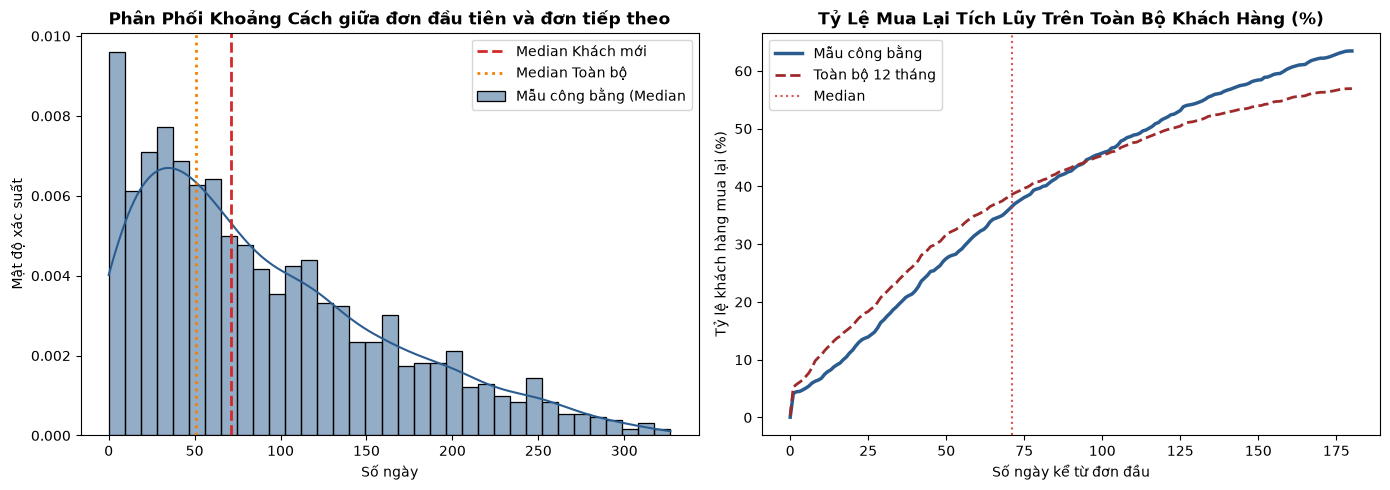

In [8]:
# Phân phối thời gian mua lại
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(s_fair, bins=35, kde=True, color="#2b5c8f", ax=ax1, stat="density", label="Mẫu công bằng (Median")
ax1.axvline(s_fair.median(), color="#d62828", linestyle="--", linewidth=2, label=f"Median Khách mới")
ax1.axvline(s_all.median(), color="#f77f00", linestyle=":", linewidth=2, label=f"Median Toàn bộ")
ax1.set_title("Phân Phối Khoảng Cách giữa đơn đầu tiên và đơn tiếp theo", fontsize=12, fontweight="bold")
ax1.set_xlabel("Số ngày")
ax1.set_ylabel("Mật độ xác suất")
ax1.legend(frameon=True)

days_grid = np.linspace(0, 180, 181)
cum_fair_all_cust = [(s_fair <= d).sum() / n_fair * 100 for d in days_grid]
cum_all_all_cust = [(s_all <= d).sum() / n_all * 100 for d in days_grid]

ax2.plot(days_grid, cum_fair_all_cust, color="#2b5c8f", linewidth=2.5, label="Mẫu công bằng")
ax2.plot(days_grid, cum_all_all_cust, color="#9e2a2b", linestyle="--", linewidth=2, label="Toàn bộ 12 tháng")
ax2.axvline(71, color="#d62828", linestyle=":", alpha=0.8, label="Median")
ax2.set_title("Tỷ Lệ Mua Lại Tích Lũy Trên Toàn Bộ Khách Hàng (%)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Số ngày kể từ đơn đầu")
ax2.set_ylabel("Tỷ lệ khách hàng mua lại (%)")
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()

1. Đoạn đầu (0 – 30 ngày): Cột cao chót vót. Mắt thường thấy ngay: Khách quay lại mua nhiều nhất là ngay trong tháng đầu tiên. Đoạn sau (sau 100, 200 ngày): Các cột thấp dần và thoải dần. Khách mua lại sau 4–6 tháng vẫn có, nhưng rải rác và thưa dần.
2. **Trung vị khoảng cách mua lại thực tế của khách mới:**
   * Trong số những khách hàng có mua lại, trung vị là **~73 ngày**. Cứ 100 khách có quay lại mua, thì 50 người sẽ mua trước ngày thứ 71, và 50 người còn lại mua sau ngày thứ 71.
3. **Ý nghĩa Tỷ lệ mua lại tích lũy:**
   * Tăng nhanh ở đầu, chậm dần về sau nhưng chưa dừng. Mỗi 30 ngày đầu tăng thêm khoảng 15–17 điểm %, đoạn 60–90 ngày còn ~11 điểm %, và từ ngày 90 đến 180 chỉ khoảng 7 điểm % mỗi 30 ngày. Đến ngày 180 đường cong vẫn đi lên chứ chưa đi ngang, nghĩa là khách vẫn tiếp tục quay lại rải rác sau nửa năm.

In [9]:
# Tính Cohort Index
inv_year = df_cohort["InvoiceDate"].dt.year
inv_month = df_cohort["InvoiceDate"].dt.month

cohort_dt = pd.to_datetime(df_cohort["CohortMonth"])
cohort_year = cohort_dt.dt.year
cohort_month = cohort_dt.dt.month

df_cohort["CohortIndex"] = (inv_year - cohort_year) * 12 + (inv_month - cohort_month)

# Ma trận số lượng khách hàng theo Cohort
cohort_cust_counts = df_cohort.groupby(["CohortMonth", "CohortIndex"])["CustomerID"].nunique().unstack()

# Kích thước ban đầu của từng Cohort
cohort_sizes = cohort_cust_counts.iloc[:, 0]

# Số lượng cohort quan sát được ở mỗi Index
cohort_n_counts = cohort_cust_counts.notna().sum(axis=0)

# Ma trận tỷ lệ giữ chân (Customer Retention Rate %)
retention_matrix = cohort_cust_counts.divide(cohort_sizes, axis=0) * 100

display(cohort_sizes.to_frame("CohortSize"))

,CohortSize
CohortMonth,
2010-12,884.0
2011-01,416.0
2011-02,380.0
2011-03,452.0
2011-04,300.0
2011-05,284.0
2011-06,242.0
2011-07,187.0
2011-08,169.0


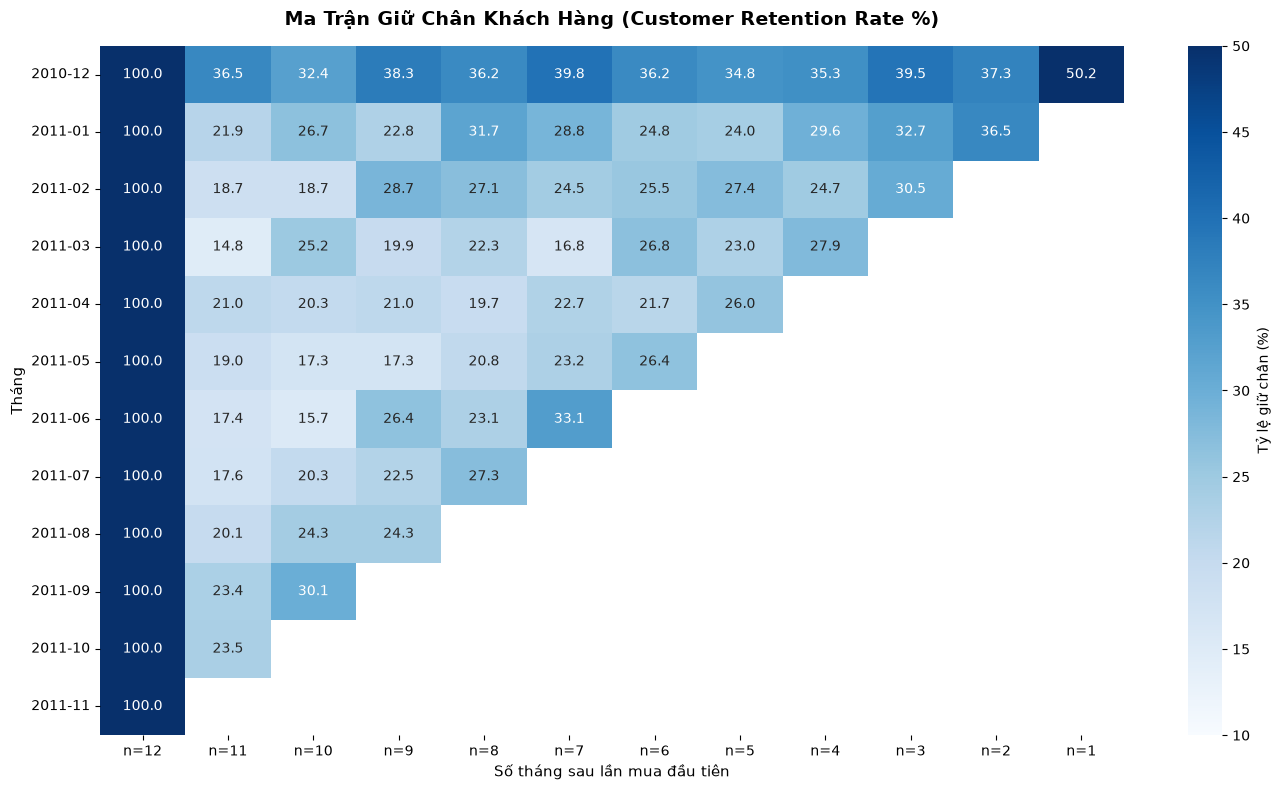

In [16]:
# Tạo nhãn trục X hiển thị số lượng cohort quan sát (n)
x_labels_with_n = [f"n={cohort_n_counts[col]}" for col in retention_matrix.columns]

plt.figure(figsize=(14, 8))
sns.heatmap(
    retention_matrix,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=10,
    vmax=50,
    cbar_kws={"label": "Tỷ lệ giữ chân (%)"}
)
plt.title("Ma Trận Giữ Chân Khách Hàng (Customer Retention Rate %)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Số tháng sau lần mua đầu tiên", fontsize=11)
plt.ylabel("Tháng", fontsize=11)
plt.xticks(ticks=np.arange(len(x_labels_with_n)) + 0.5, labels=x_labels_with_n, rotation=0)
plt.tight_layout()
plt.show()

,Số Cohort (n),Toàn bộ: Giản đơn (%),Toàn bộ: Có trọng số (%),Khách mới 2011: Giản đơn (%),Khách mới 2011: Có trọng số (%),"Lệch do 12/2010 (Trọng số, điểm %)"
CohortIndex,,,,,,
0,12,100.00,100.00,100.00,100.00,0.00
1,11,21.27,23.48,19.75,19.73,3.74
2,10,23.09,24.88,22.06,22.46,2.42
3,9,24.58,26.92,22.86,22.76,4.16
4,8,26.03,28.01,24.58,24.81,3.20
5,7,26.99,28.90,24.85,24.25,4.65
6,6,26.89,28.76,25.03,25.16,3.59
7,5,27.05,28.54,25.10,24.94,3.60
8,4,29.37,30.72,27.39,27.48,3.24


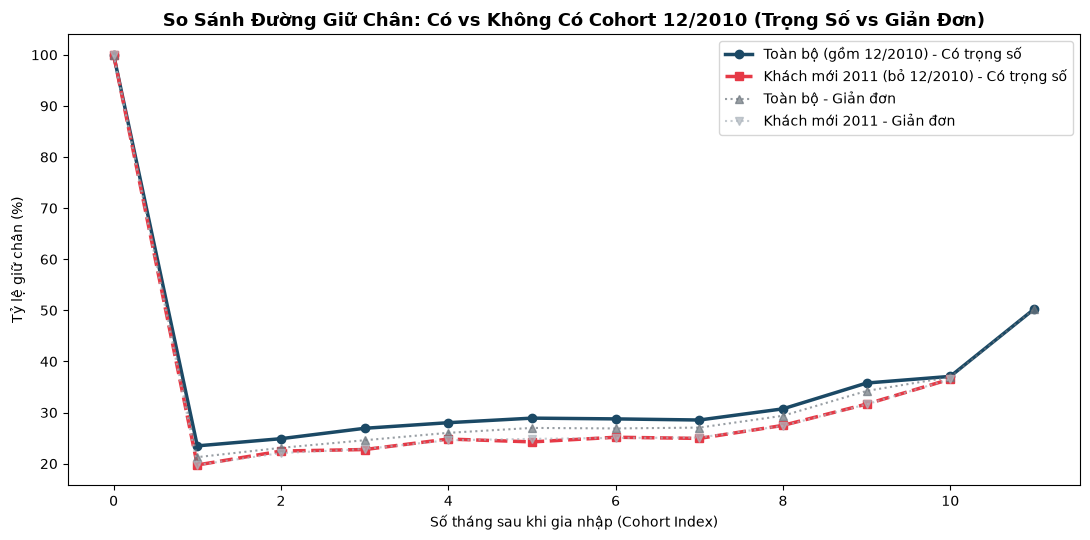

In [17]:
unweighted_all = retention_matrix.mean(axis=0)
unweighted_pure = retention_matrix.iloc[1:].mean(axis=0)

weighted_all = cohort_cust_counts.sum(axis=0) / cohort_cust_counts.notna().multiply(cohort_sizes, axis=0).sum(axis=0) * 100

cohort_cust_pure = cohort_cust_counts.iloc[1:]
cohort_sizes_pure = cohort_sizes.iloc[1:]
weighted_pure = cohort_cust_pure.sum(axis=0) / cohort_cust_pure.notna().multiply(cohort_sizes_pure, axis=0).sum(axis=0) * 100

comparison_df = pd.DataFrame({
    "Số Cohort (n)": cohort_n_counts,
    "Toàn bộ: Giản đơn (%)": unweighted_all,
    "Toàn bộ: Có trọng số (%)": weighted_all,
    "Khách mới 2011: Giản đơn (%)": unweighted_pure,
    "Khách mới 2011: Có trọng số (%)": weighted_pure,
    "Lệch do 12/2010 (Trọng số, điểm %)": weighted_all - weighted_pure
})

display(comparison_df.round(2))

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(comparison_df.index, comparison_df["Toàn bộ: Có trọng số (%)"], marker="o", label="Toàn bộ (gồm 12/2010) - Có trọng số", color="#1b4965", linewidth=2.5)
ax.plot(comparison_df.index[:-1], comparison_df["Khách mới 2011: Có trọng số (%)"].dropna(), marker="s", linestyle="--", label="Khách mới 2011 (bỏ 12/2010) - Có trọng số", color="#e63946", linewidth=2.5)
ax.plot(comparison_df.index, comparison_df["Toàn bộ: Giản đơn (%)"], marker="^", linestyle=":", label="Toàn bộ - Giản đơn", color="#6c757d", alpha=0.7)
ax.plot(comparison_df.index[:-1], comparison_df["Khách mới 2011: Giản đơn (%)"].dropna(), marker="v", linestyle=":", label="Khách mới 2011 - Giản đơn", color="#adb5bd", alpha=0.7)

ax.set_title("So Sánh Đường Giữ Chân: Có vs Không Có Cohort 12/2010 (Trọng Số vs Giản Đơn)", fontsize=13, fontweight="bold")
ax.set_xlabel("Số tháng sau khi gia nhập (Cohort Index)")
ax.set_ylabel("Tỷ lệ giữ chân (%)")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

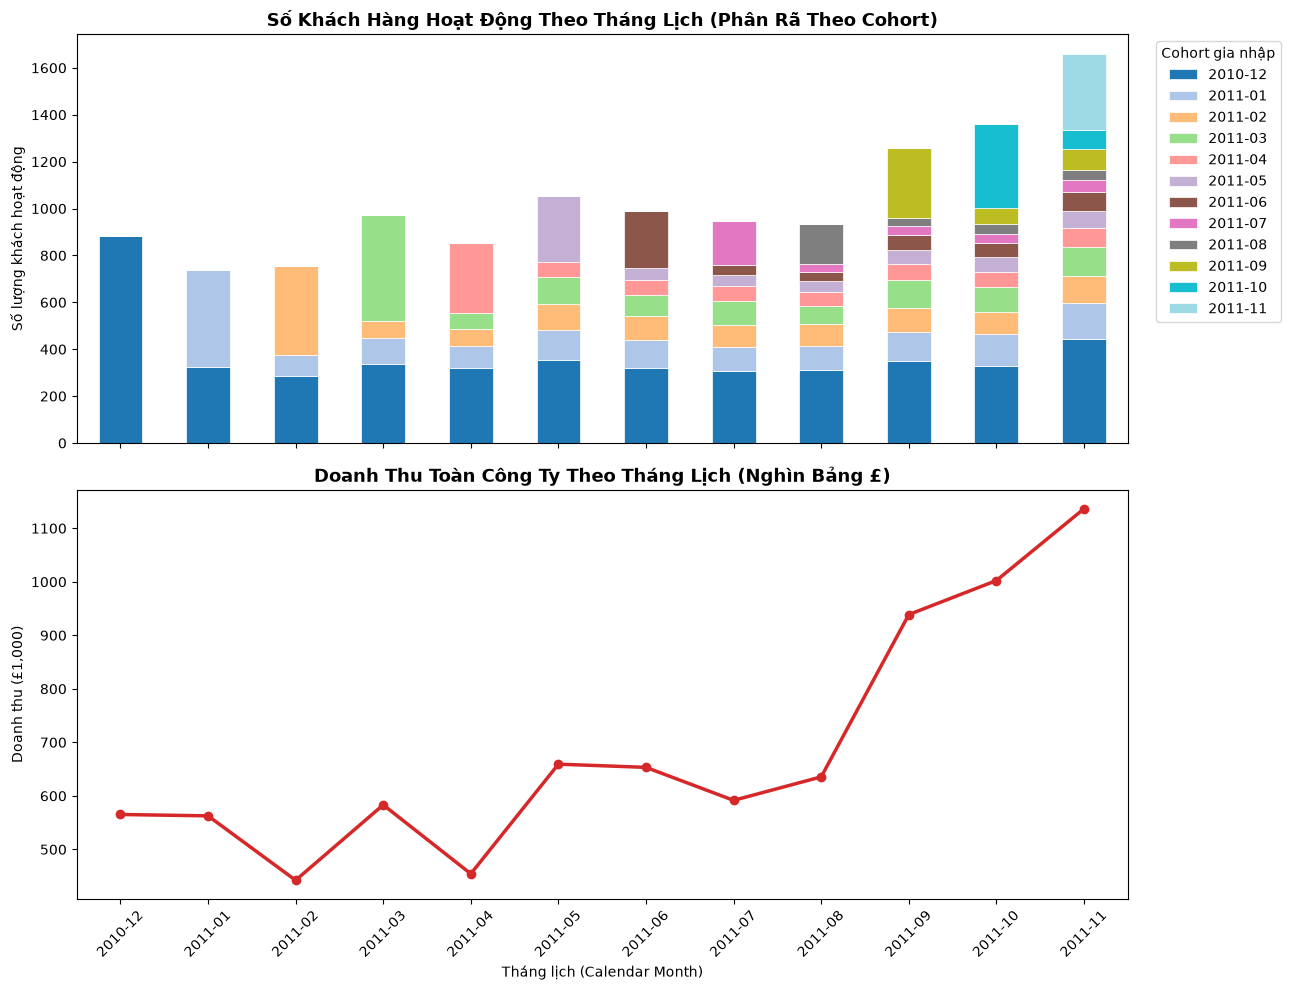

In [18]:
# Kiểm tra số lượng khách hàng hoạt động mỗi tháng lịch, phân rã theo Cohort gia nhập
calendar_activity = df_cohort.groupby(["InvoiceMonth", "CohortMonth"])["CustomerID"].nunique().unstack(fill_value=0)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 10), sharex=True)

calendar_activity.plot(kind="bar", stacked=True, colormap="tab20", ax=ax1, edgecolor="white", linewidth=0.5)
ax1.set_title("Số Khách Hàng Hoạt Động Theo Tháng Lịch (Phân Rã Theo Cohort)", fontsize=13, fontweight="bold")
ax1.set_ylabel("Số lượng khách hoạt động")
ax1.legend(title="Cohort gia nhập", bbox_to_anchor=(1.02, 1), loc="upper left")

monthly_revenue = df_cohort.groupby("InvoiceMonth")["TotalAmount"].sum() / 1000
monthly_revenue.plot(kind="line", marker="o", color="#d62828", linewidth=2.5, ax=ax2)
ax2.set_title("Doanh Thu Toàn Công Ty Theo Tháng Lịch (Nghìn Bảng £)", fontsize=13, fontweight="bold")
ax2.set_ylabel("Doanh thu (£1,000)")
ax2.set_xlabel("Tháng lịch (Calendar Month)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Nhận Xét Về Mùa Vụ Q4 và Quy Mô Mẫu ở Các Index Cuối:
1. Doanh thu Q4 tăng gần gấp đôi (từ ~600k lên >1,1 triệu £): Cú hích mùa vụ Giáng sinh làm bùng nổ cả lượng khách mới lẫn khách cũ quay lại mua sắm.
2. Hiện tượng giữ chân tăng ở Index 9–10 là do mùa vụ, không phải do độ trung thành: Điểm rơi của các tháng này trùng khớp với đợt cao điểm tháng 10–11/2011.
3. Cần tách riêng khách cũ (Cohort 12/2010): Chân cột màu xanh đậm quá lớn, nếu tính gộp sẽ làm lệch thước đo giữ chân của khách mới.

Để kiểm tra xem hiện tượng "Revenue Expansion" có thực sự tồn tại ở khách hàng mới hay chỉ là sản phẩm của Cohort 12/2010, ta phân rã doanh thu:
$$\text{Doanh thu} = \text{Số khách hoạt động} \times \text{Số đơn/khách} \times \text{AOV (Giá trị trung bình/đơn)}$$

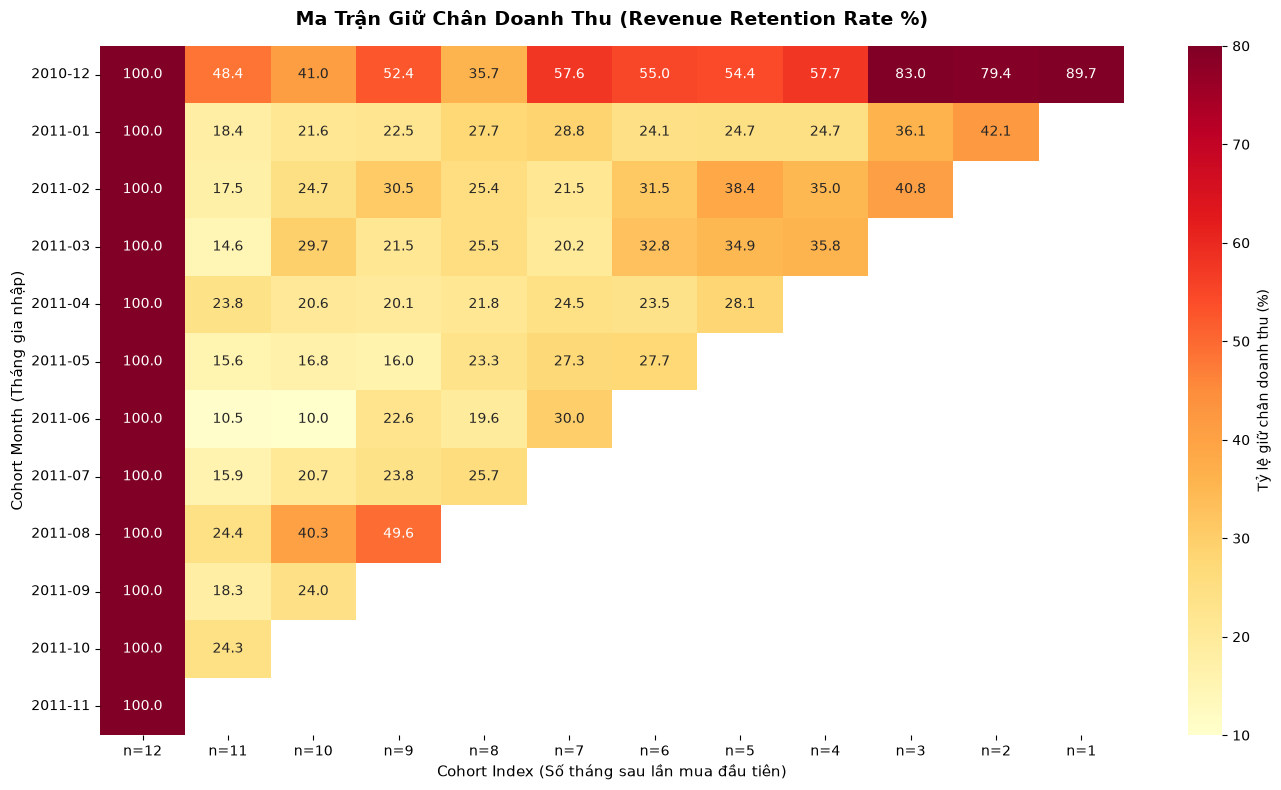

In [19]:
# Ma trận doanh thu tổng của từng Cohort
cohort_revenue = df_cohort.groupby(["CohortMonth", "CohortIndex"])["TotalAmount"].sum().unstack()
cohort_rev_size = cohort_revenue.iloc[:, 0]

# Ma trận tỷ lệ doanh thu so với tháng ban đầu (Revenue Retention Rate %)
rev_retention_matrix = cohort_revenue.divide(cohort_rev_size, axis=0) * 100

plt.figure(figsize=(14, 8))
sns.heatmap(
    rev_retention_matrix,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=10,
    vmax=80,
    cbar_kws={"label": "Tỷ lệ giữ chân doanh thu (%)"}
)
plt.title("Ma Trận Giữ Chân Doanh Thu (Revenue Retention Rate %)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Cohort Index (Số tháng sau lần mua đầu tiên)", fontsize=11)
plt.ylabel("Cohort Month (Tháng gia nhập)", fontsize=11)
plt.xticks(ticks=np.arange(len(x_labels_with_n)) + 0.5, labels=x_labels_with_n, rotation=0)
plt.tight_layout()
plt.show()

In [20]:
rev_per_active = cohort_revenue / cohort_cust_counts

base_rpa = rev_per_active.iloc[:, 0]
rel_rpa = rev_per_active.divide(base_rpa, axis=0) * 100

rpa_comparison = pd.DataFrame({
    "Số Cohort (n)": cohort_n_counts,
    "12/2010: Revenue Retention (%)": rev_retention_matrix.loc["2010-12"],
    "Khách mới: Revenue Retention (%)": rev_retention_matrix.iloc[1:].mean(axis=0),
    "12/2010: Doanh thu/Khách (£)": rev_per_active.loc["2010-12"],
    "Khách mới: Doanh thu/Khách (£)": rev_per_active.iloc[1:].mean(axis=0),
    "12/2010: Tỷ lệ RPA vs Tháng 0 (%)": rel_rpa.loc["2010-12"],
    "Khách mới: Tỷ lệ RPA vs Tháng 0 (%)": rel_rpa.iloc[1:].mean(axis=0)
})

print("--- PHÂN RÃ DOANH THU: COHORT 12/2010 VS CÁC COHORT MỚI 2011 ---")
display(rpa_comparison.round(1))

new_cust_2011 = cohort_sizes.iloc[1:].sum()
annualized_new_cust = new_cust_2011 / 11 * 12 
rpa_m1_pure = cohort_revenue.iloc[1:, 1].sum() / cohort_cust_counts.iloc[1:, 1].sum()

added_cust_annual = annualized_new_cust * 0.02
added_revenue_annual = added_cust_annual * rpa_m1_pure

print(f"Số khách mới năm 2011 (11 tháng): {new_cust_2011:,.0f} khách (Quy năm 12 tháng: {annualized_new_cust:,.0f} khách)")
print(f"Doanh thu trung bình trên mỗi khách hoạt động ở Tháng 1 (RPA Month 1): £{rpa_m1_pure:.2f}")
print(f"Số khách giữ lại thêm mỗi năm: ~{added_cust_annual:.1f} khách")
print(f"Doanh thu tăng thêm ước tính mỗi năm (Gross): ~£{added_revenue_annual:,.2f}")

--- PHÂN RÃ DOANH THU: COHORT 12/2010 VS CÁC COHORT MỚI 2011 ---


,Số Cohort (n),12/2010: Revenue Retention (%),Khách mới: Revenue Retention (%),12/2010: Doanh thu/Khách (£),Khách mới: Doanh thu/Khách (£),12/2010: Tỷ lệ RPA vs Tháng 0 (%),Khách mới: Tỷ lệ RPA vs Tháng 0 (%)
CohortIndex,,,,,,,
0,12,100.0,100.0,639.4,467.2,100.0,100.0
1,11,48.4,18.3,847.2,430.8,132.5,92.5
2,10,41.0,23.2,810.9,484.2,126.8,104.6
3,9,52.4,25.8,874.3,524.5,136.8,112.2
4,8,35.7,24.1,631.2,461.8,98.7,99.5
5,7,57.6,25.4,925.6,500.5,144.8,104.0
6,6,55.0,27.9,971.7,518.2,152.0,111.3
7,5,54.4,31.5,998.1,596.6,156.1,125.7
8,4,57.7,31.8,1046.1,574.9,163.6,117.8


Số khách mới năm 2011 (11 tháng): 3,409 khách (Quy năm 12 tháng: 3,719 khách)
Doanh thu trung bình trên mỗi khách hoạt động ở Tháng 1 (RPA Month 1): £440.50
Số khách giữ lại thêm mỗi năm: ~74.4 khách
Doanh thu tăng thêm ước tính mỗi năm (Gross): ~£32,763.31


### Kết Luận Khoa Học Sau Khi Rà Soát:
1. **Bác bỏ giả thuyết AOV tăng theo độ gắn bó ở khách mới:**
   * Ở Cohort 12/2010, doanh thu trên mỗi khách hoạt động tăng từ **132% đến 212%** so với Tháng 0. Đây là tệp khách sỉ lớn lâu năm (Whales) cộng hưởng với đỉnh mua hàng mùa lễ hội.
   * Ngược lại, ở các cohort khách mới năm 2011, doanh thu trên mỗi khách hoạt động chỉ dao động quanh **92% – 125%** (bình quân xấp xỉ **100%**). Không có bằng chứng cho thấy khách mới gắn bó thì giá trị đơn hàng (AOV) sẽ tự động mở rộng (Revenue Expansion).
2. **Độ tập trung doanh thu (Pareto):**
   * Doanh thu giữ chân cao ở 12/2010 thực chất phản ánh độ tập trung doanh thu cực lớn: Top 20% khách hàng đóng góp tới ~74% doanh thu công ty.
3. **Căn cứ vững chắc cho Notebook 03 (RFM) & Notebook 04 (Insights):**
   * **Ngưỡng Recency:** Dựa trên phân vị quintile thực tế ngày 10/12/2011: R=5 ($\le 14$ ngày), R=4 (15-32 ngày), R=3 (33-71 ngày), R=2 (72-179 ngày), R=1 (> 179 ngày).
   * **Ngưỡng Frequency:** Phân phối rời rạc `[0, 1, 2, 3, 5, inf]` cho 4.326 khách hàng (trừ 8 khách Zero Net).
   * **Kế hoạch tương tác:** Dựa trên phân tích xác suất có điều kiện (Hazard table) với mốc Median khách mới là 71 ngày.
   * **Kế hoạch Q4:** Được định vị là giả thuyết cần theo dõi kiểm chứng trong các năm tiếp theo.